<a href="https://colab.research.google.com/github/saradom11/Investigacion-de-operaciones-/blob/main/Modelo_SIR_MCMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="text-align:center; background:#F3E5F5; padding:24px; border-radius:16px;">
<font face="Georgia" size="5" color="#6A1B9A"><b>Modelo SIR MCMC</b></font><br>
</div>

**Materia**: Investigación de operaciones

**Alumna:** Arredondo Domínguez Sara Itzel

**En el notebook:** Muestro el modelo epidemiológico SIR y los datos de infectados del repositorio para explorar valores de los parámetros $\beta$ y $\gamma$. El código se presenta por etapas para que sea más sencillo identificar los datos, las ecuaciones, la función de discrepancia y el procedimiento de muestreo.



---
<font face="Georgia" size="5" color="#7B1FA2"><b>1. Bibliotecas</b></font>

En esta sección se importan las herramientas necesarias para realizar los cálculos numéricos, organizar los datos, resolver las ecuaciones diferenciales y construir gráficas. Se conservan las bibliotecas que utiliza el código.



In [7]:
# Importamos las bibliotecas para cálculo numérico, tablas, gráficas e integración de EDO

# Bibliotecas para resolver el sistema SIR y analizar los resultados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import odeint

# Estilo visual en tonos morados
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["figure.figsize"] = (9, 5.5)

# Semilla para que la simulación aleatoria sea reproducible
np.random.seed(2026)

---
<font face="Georgia" size="5" color="#7B1FA2"><b>2. Datos</b></font>

Los datos observados representan el número de personas infectadas en cada uno de los tiempos considerados. También se definen el tamaño de la población y las condiciones iniciales que necesita el modelo SIR.

La variable `datos_school` contiene las observaciones que se compararán con las predicciones del modelo. Las condiciones iniciales describen cuántas personas comienzan como susceptibles, infectadas y recuperadas.

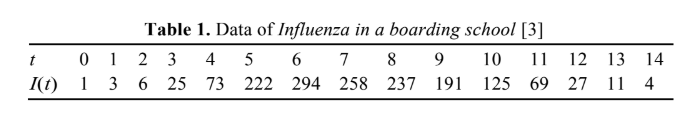

,Observación,Tiempo,Infectados observados
0,1,0.000000,1
1,2,1.071429,3
2,3,2.142857,6
3,4,3.214286,25
4,5,4.285714,73
5,6,5.357143,222
6,7,6.428571,294
7,8,7.500000,258
8,9,8.571429,237
9,10,9.642857,191


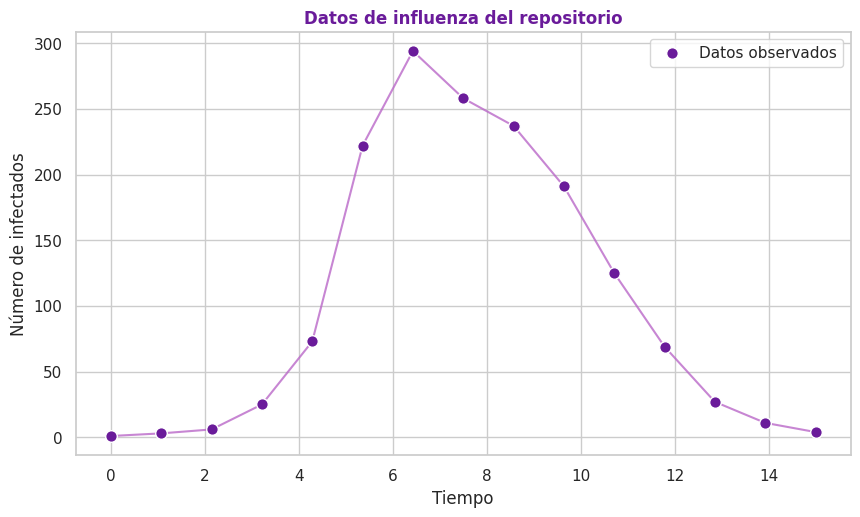

In [8]:
# Guardamos las observaciones como un arreglo numérico para compararlas con el modelo

# Datos observados
datos_school = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4],dtype=float)

# Constantes y condiciones iniciales del repositorio
N = 763
I0, R0 = 1, 0
S0 = N - I0 - R0
y0 = [S0, I0, R0]

# Vector temporal
t_obs = np.linspace(0, 15, 15)

# Tabla para revisar las observaciones
datos = pd.DataFrame({"Observación": np.arange(1, len(datos_school) + 1),"Tiempo": t_obs,"Infectados observados": datos_school.astype(int)})
display(datos)

# Gráfica inicial de los datos
plt.figure(figsize=(10, 5.5))
plt.plot(t_obs, datos_school, color="#BA68C8", linewidth=1.5, alpha=0.8)
plt.scatter(t_obs, datos_school, color="#6A1B9A", edgecolor="white",s=70, zorder=3, label="Datos observados")
plt.title("Datos de influenza del repositorio", color="#6A1B9A", fontweight="bold")
plt.xlabel("Tiempo")
plt.ylabel("Número de infectados")
plt.legend()
plt.show()

---
<font face="Georgia" size="5" color="#7B1FA2"><b>3. Modelo SIR</b></font>

El modelo divide a la población en tres grupos:

- $S(t)$: personas susceptibles de infectarse.
- $I(t)$: personas infectadas que pueden transmitir la enfermedad.
- $R(t)$: personas recuperadas o retiradas de la transmisión.

Las ecuaciones diferenciales del modelo son:

$$\frac{dS}{dt}=-\beta\frac{SI}{N},\qquad
\frac{dI}{dt}=\beta\frac{SI}{N}-\gamma I,\qquad
\frac{dR}{dt}=\gamma I$$

Aquí $\beta$ es la tasa de transmisión, $\gamma$ es la tasa de recuperación y $N$ es la población total.



In [9]:
# Definimos las ecuaciones diferenciales que describen la evolución de S, I y R

def deriv(estado, tiempo, beta, gamma):   # Calcula las derivadas dS/dt, dI/dt y dR/dt del modelo SIR
    S, I, R = estado

    # Ecuaciones diferenciales
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    return dSdt, dIdt, dRdt


def resolver_sir(beta, gamma, tiempos=t_obs):   # Resuelve el sistema SIR y devuelve S(t), I(t), R(t)
    # odeint integra las ecuaciones diferenciales en los tiempos solicitados
    solucion = odeint(deriv, y0, tiempos, args=(beta, gamma))
    S, I, R = solucion.T
    return S, I, R

# Comprobamos la función con valores iniciales de beta y gamma
beta_prueba = 8e-4
gamma_prueba = 0.25
S_prueba, I_prueba, R_prueba = resolver_sir(beta_prueba, gamma_prueba)

print("Primeros cinco valores de infectados calculados:")
print(np.round(I_prueba[:5], 3))

Primeros cinco valores de infectados calculados:
[1.    1.47  2.158 3.165 4.633]


---
<font face="Georgia" size="5" color="#7B1FA2"><b>4. Función de discrepancia del repositorio</b></font>

Para comparar la trayectoria calculada por el modelo con las observaciones, se utiliza la función de discrepancia definida a partir del repositorio. Un valor menor indica que las predicciones y los datos observados presentan una discrepancia menor según esta medida.

La función recibe $\beta$ y $\gamma$, resuelve el modelo SIR y calcula la diferencia entre los infectados predichos y los observados. También verifica que los parámetros y los resultados sean válidos antes de devolver la discrepancia.



In [10]:
# Esta función cuantifica la discrepancia entre los infectados simulados y los observados.

def discrepancia_chi2(beta, gamma):   # Calcula la discrepancia tipo Pearson usada por el repositorio
    # Los parámetros deben ser positivos y finitos
    if (not np.isfinite(beta) or not np.isfinite(gamma)
            or beta <= 0 or gamma <= 0):
        return np.inf
    try:
        _, I_pred, _ = resolver_sir(beta, gamma)
    except (ValueError, RuntimeError, FloatingPointError):
        return np.inf

    # Si la solución no es numéricamente válida, descartamos el resultado
    if not np.all(np.isfinite(I_pred)):
        return np.inf

    # El denominador se limita para evitar divisiones entre cero
    denominador = np.maximum(I_pred, 1e-8)
    chi2 = np.sum((datos_school - I_pred)**2 / denominador)
    return float(chi2)


print("Discrepancia en los valores de prueba:",discrepancia_chi2(beta_prueba, gamma_prueba))

Discrepancia en los valores de prueba: 23990.339480281815


---
<font face="Georgia" size="5" color="#7B1FA2"><b>5. Distribución objetivo para MCMC</b></font>

Para aplicar MCMC se define una distribución objetivo para los parámetros. En este código se combina una distribución previa uniforme, limitada a  intervalos de $\beta$ y $\gamma$, con la medida de ajuste calculada en la sección anterior.

La función `log_prior` determina si los parámetros están dentro de los intervalos permitidos. La función `log_posterior` utiliza esa condición y la discrepancia para asignar una puntuación a cada propuesta; los valores fuera de los límites no se consideran admisibles.



In [11]:
# Definimos la distribución previa y la función objetivo que utilizará el muestreo.

# Intervalos uniformes
BETA_MIN, BETA_MAX = 1e-7, 5e-3
GAMMA_MIN, GAMMA_MAX = 0.01, 2.0

def log_prior(beta, gamma):
    """Log-prior uniforme: cero dentro de los límites y -infinito fuera."""
    if BETA_MIN < beta < BETA_MAX and GAMMA_MIN < gamma < GAMMA_MAX:
        return 0.0
    return -np.inf

def log_posterior(beta, gamma):
    """Logaritmo de la densidad objetivo usada para generar las cadenas MCMC."""
    lp = log_prior(beta, gamma)

    # Si un parámetro queda fuera del prior, el punto no es admisible
    if not np.isfinite(lp):
        return -np.inf
    chi2 = discrepancia_chi2(beta, gamma)
    if not np.isfinite(chi2):
        return -np.inf

    # Densidad proporcional a exp(-chi2/2), calculada en escala logarítmica
    return lp - 0.5 * chi2


print("Log-posterior en el punto de prueba:",log_posterior(beta_prueba, gamma_prueba))

Log-posterior en el punto de prueba: -11995.169740140907


---
<font face="Georgia" size="5" color="#7B1FA2"><b>6. MCMC mediante Metropolis-Hastings</b></font>

En esta sección se aplica el procedimiento de Metropolis-Hastings para generar una cadena de valores candidatos de $\beta$ y $\gamma$. En cada iteración se propone un nuevo par de parámetros y se compara su valor de log-posterior con el de la posición actual para decidir si se acepta la propuesta.

Al finalizar, se descarta el periodo inicial de calentamiento y se resumen las muestras restantes. El código también muestra las cadenas, las distribuciones posteriores y la comparación entre los infectados observados y la trayectoria SIR ajustada.



Beta estimado: 0.00204765
Gamma estimado: 0.43463330
Tasa de aceptación: 4.04%
IC 95% beta: 0.00201253 - 0.00208643
IC 95% gamma: 0.41457846 - 0.45504354


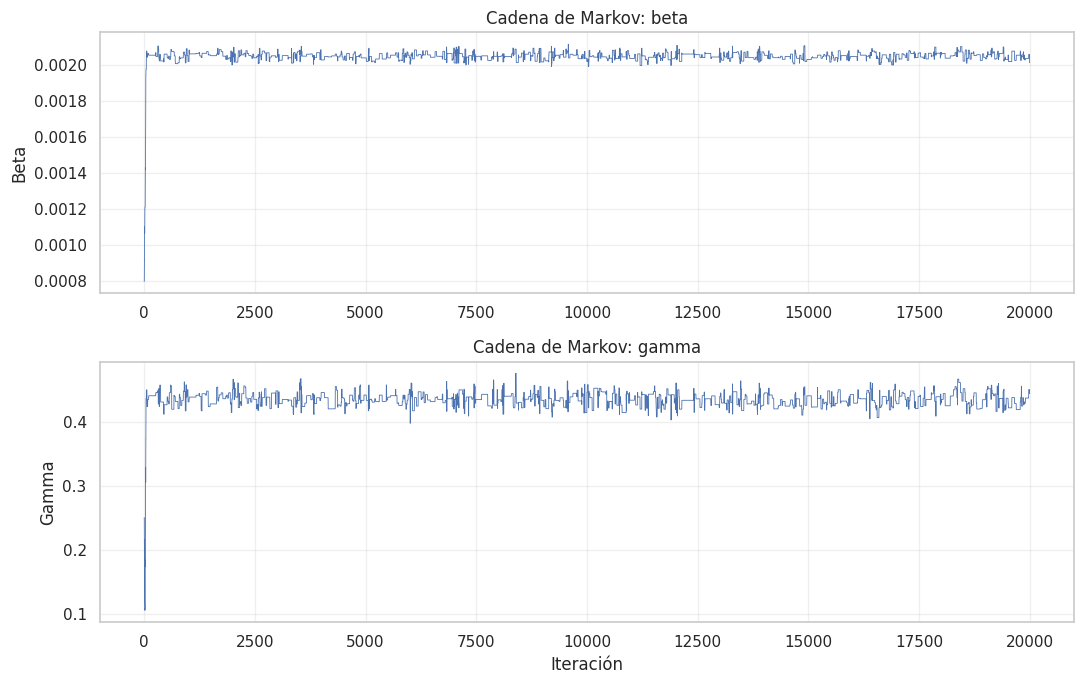

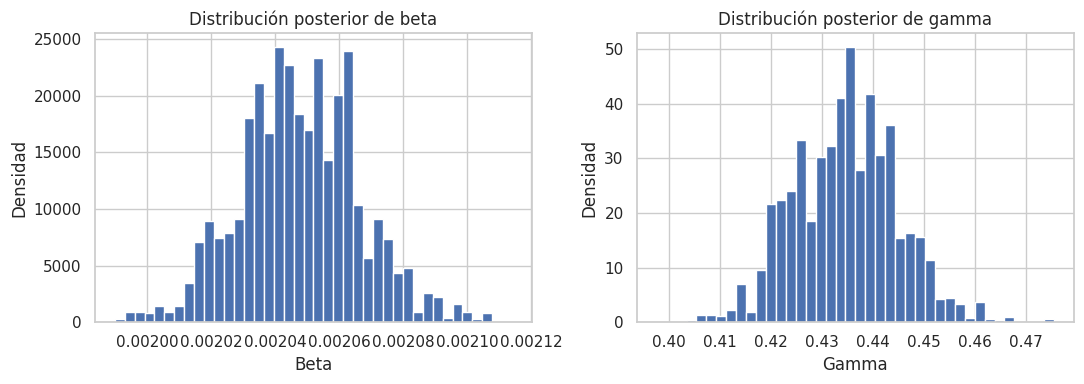

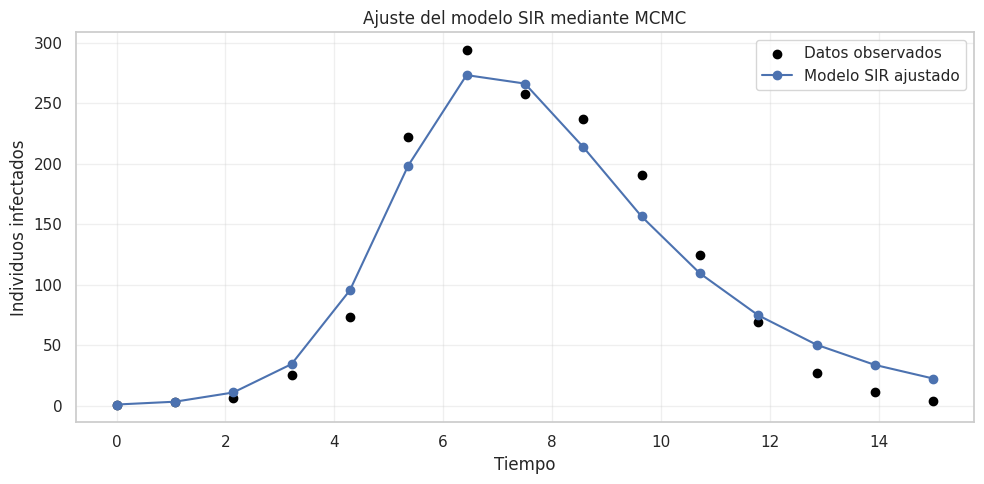

In [12]:
# Bibliotecas para cálculos, gráficas e integración del sistema SIR
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Datos y condiciones iniciales tomados del repositorio de referencia
N = 763
I0 = 1
R0 = 0
S0 = N - I0 - R0
t_obs = np.linspace(0, 15, 15)
datos_school = np.array([1, 3, 6, 25, 73, 222, 294, 258,237, 191, 125, 69, 27, 11, 4])

# Ecuaciones diferenciales del modelo SIR
def modelo_sir(y, t, beta, gamma):
    S, I, R = y
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]


# Integra las ecuaciones y devuelve la trayectoria de infectados
def resolver_sir(beta, gamma):
    solucion = odeint(modelo_sir,[S0, I0, R0],t_obs,args=(beta, gamma))
    return solucion[:, 1]


# Calcula la discrepancia entre los datos y la predicción del modelo
def chi_cuadrada(beta, gamma):
    if not (1e-7 < beta < 5e-3 and 0.01 < gamma < 2.0):
        return np.inf
    try:
        prediccion = resolver_sir(beta, gamma)
        if (
            not np.all(np.isfinite(prediccion))
            or np.any(prediccion <= 0)
        ):
            return np.inf
        return np.sum((prediccion - datos_school) ** 2 / prediccion)
    except (ValueError, RuntimeError, OverflowError):
        return np.inf


# Evalúa la función objetivo en la escala logarítmica usada por el muestreo
def log_posterior(beta, gamma):
    if not (1e-7 < beta < 5e-3 and 0.01 < gamma < 2.0):
        return -np.inf
    chi2 = chi_cuadrada(beta, gamma)
    if not np.isfinite(chi2):
        return -np.inf
    return -0.5 * chi2


# Genera propuestas de parámetros y decide si cada una se acepta.
def metropolis_hastings(
    beta_inicial,
    gamma_inicial,
    iteraciones=20000,
    salto_beta=1e-4,
    salto_gamma=0.08,
    semilla=123
):
    rng = np.random.default_rng(semilla)
    muestras = np.zeros((iteraciones, 2))
    beta_actual = beta_inicial
    gamma_actual = gamma_inicial
    logp_actual = log_posterior(beta_actual, gamma_actual)
    aceptaciones = 0

    for i in range(iteraciones):
        beta_propuesto = rng.normal(beta_actual, salto_beta)
        gamma_propuesto = rng.normal(gamma_actual, salto_gamma)
        logp_propuesto = log_posterior(beta_propuesto,gamma_propuesto)

        if np.log(rng.random()) < min(0, logp_propuesto - logp_actual):
            beta_actual = beta_propuesto
            gamma_actual = gamma_propuesto
            logp_actual = logp_propuesto
            aceptaciones += 1

        muestras[i] = [beta_actual, gamma_actual]

    tasa_aceptacion = aceptaciones / iteraciones
    return muestras, tasa_aceptacion


# Ejecuta la cadena y guarda las muestras obtenidas
muestras, tasa_aceptacion = metropolis_hastings(
    beta_inicial=8e-4,
    gamma_inicial=0.25,
    iteraciones=20000
)

# Excluye las primeras iteraciones antes de resumir las muestras
burn_in = 5000
muestras_validas = muestras[burn_in:]

beta_muestras = muestras_validas[:, 0]
gamma_muestras = muestras_validas[:, 1]

# Resume los parámetros mediante promedios e intervalos percentiles
beta_estimado = np.mean(beta_muestras)
gamma_estimado = np.mean(gamma_muestras)

print(f"Beta estimado: {beta_estimado:.8f}")
print(f"Gamma estimado: {gamma_estimado:.8f}")
print(f"Tasa de aceptación: {tasa_aceptacion:.2%}")
print(f"IC 95% beta: "f"{np.percentile(beta_muestras, 2.5):.8f} - "f"{np.percentile(beta_muestras, 97.5):.8f}")
print(f"IC 95% gamma: "f"{np.percentile(gamma_muestras, 2.5):.8f} - "f"{np.percentile(gamma_muestras, 97.5):.8f}")

# Permite inspeccionar cómo cambian los parámetros a lo largo de las iteraciones
fig, ax = plt.subplots(2, 1, figsize=(11, 7))

ax[0].plot(muestras[:, 0], linewidth=0.6)
ax[0].set_title("Cadena de Markov: beta")
ax[0].set_ylabel("Beta")
ax[0].grid(alpha=0.3)

ax[1].plot(muestras[:, 1], linewidth=0.6)
ax[1].set_title("Cadena de Markov: gamma")
ax[1].set_ylabel("Gamma")
ax[1].set_xlabel("Iteración")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Muestra la distribución empírica de las muestras conservadas
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(beta_muestras, bins=40, density=True)
ax[0].set_title("Distribución posterior de beta")
ax[0].set_xlabel("Beta")
ax[0].set_ylabel("Densidad")

ax[1].hist(gamma_muestras, bins=40, density=True)
ax[1].set_title("Distribución posterior de gamma")
ax[1].set_xlabel("Gamma")
ax[1].set_ylabel("Densidad")

plt.tight_layout()
plt.show()

# Compara las observaciones con la trayectoria calculada usando los parámetros estimados
solucion_ajustada = odeint(modelo_sir,[S0, I0, R0],t_obs,args=(beta_estimado, gamma_estimado))

plt.figure(figsize=(10, 5))
plt.scatter(t_obs, datos_school, color="black", label="Datos observados")
plt.plot(t_obs,solucion_ajustada[:, 1],marker="o",label="Modelo SIR ajustado")
plt.title("Ajuste del modelo SIR mediante MCMC")
plt.xlabel("Tiempo")
plt.ylabel("Individuos infectados")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()